# Bank Customer Churn Prediction - Deep Learning

## 1. Introduction
This notebook develops an Artificial Neural Network (ANN) to predict bank customer churn.

## 2. Deep Learning Approach
- Artificial Neural Network (ANN)
- Input Layer
- Hidden Layers
- Output Layer

## 3. Model Evaluation
- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- Confusion Matrix

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from pathlib import Path
import joblib

print("TensorFlow Version:", tf.__version__)
print("Deep Learning libraries imported successfully!")

TensorFlow Version: 2.21.0
Deep Learning libraries imported successfully!


In [2]:
# Define project directory
from pathlib import Path

BASE_DIR = Path.cwd().parent

# Load original dataset
DATA_PATH = BASE_DIR / "dataset" / "Churn_Modelling.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
# Separate input features and target variable

X = df.drop(columns=[
    "RowNumber",
    "CustomerId",
    "Surname",
    "Exited"
])

y = df["Exited"]

print("Input Features:", X.shape)
print("Target Variable:", y.shape)

Input Features: (10000, 10)
Target Variable: (10000,)


In [4]:
# Split into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 10)
Testing Data: (2000, 10)


In [5]:
# Identify categorical features
categorical_features = ["Geography", "Gender"]

# Identify numerical features
numerical_features = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary"
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['Geography', 'Gender']
Numerical features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


In [6]:
# Create preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("ANN preprocessing pipeline created successfully!")

ANN preprocessing pipeline created successfully!


In [7]:
# Fit on training data and transform both datasets

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert to dense arrays if necessary
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

# Convert to float32 for TensorFlow
X_train_processed = X_train_processed.astype("float32")
X_test_processed = X_test_processed.astype("float32")

# Convert target variables to NumPy arrays
y_train_dl = y_train.to_numpy().astype("float32")
y_test_dl = y_test.to_numpy().astype("float32")

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)
print("Preprocessing completed successfully!")

Training data shape: (8000, 13)
Testing data shape: (2000, 13)
Preprocessing completed successfully!


In [8]:
# Build Artificial Neural Network

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

ann_model = Sequential([
    # Input layer and first hidden layer
    Dense(64, activation="relu",
          input_shape=(X_train_processed.shape[1],)),

    Dropout(0.3),

    # Second hidden layer
    Dense(32, activation="relu"),

    Dropout(0.2),

    # Output layer
    Dense(1, activation="sigmoid")
])

print("ANN model created successfully!")

ANN model created successfully!


c:\Users\navya\Documents\Bank-Customer-Churn\venv\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,009 (11.75 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Compile ANN model

ann_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("ANN model compiled successfully!")

ANN model compiled successfully!


In [11]:
# Train ANN model

from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = ann_model.fit(
    X_train_processed,
    y_train_dl,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("ANN training completed successfully!")

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7948 - loss: 0.4831 - val_accuracy: 0.8131 - val_loss: 0.4337
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8108 - loss: 0.4338 - val_accuracy: 0.8419 - val_loss: 0.4085
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8220 - loss: 0.4167 - val_accuracy: 0.8587 - val_loss: 0.3839
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8327 - loss: 0.3937 - val_accuracy: 0.8631 - val_loss: 0.3571
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8428 - loss: 0.3819 - val_accuracy: 0.8675 - val_loss: 0.3437
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.8442 - loss: 0.3706 - val_accuracy: 0.8662 - val_loss: 0.3389
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8461 - loss: 0.3638 - val_accuracy: 0.8700 - val_loss: 0.3362
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.8438 - loss: 0.3690 - val_accuracy:

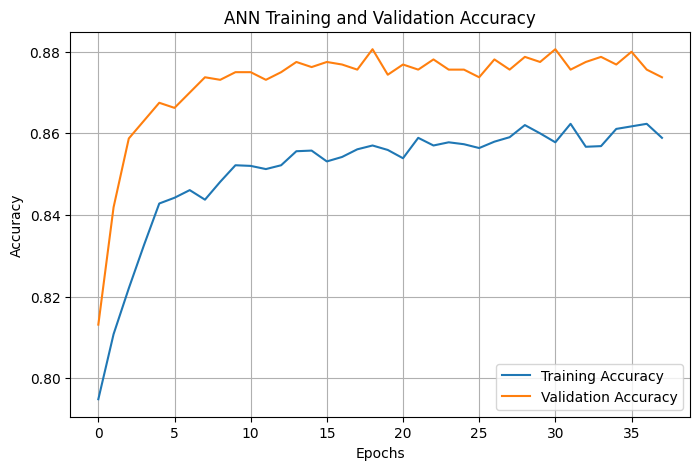

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("ANN Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

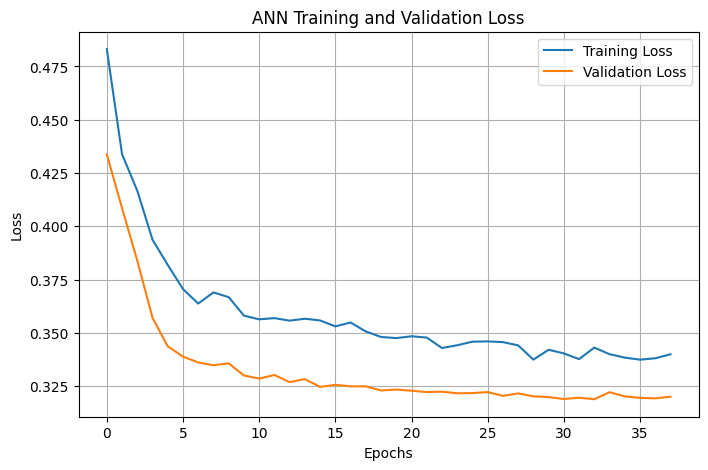

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("ANN Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [14]:
# Generate predictions on test data

y_prob_ann = ann_model.predict(X_test_processed).ravel()

# Convert probabilities into class predictions
y_pred_ann = (y_prob_ann >= 0.5).astype(int)

print("ANN predictions generated successfully!")

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
ANN predictions generated successfully!


In [15]:
# Evaluate ANN model

ann_accuracy = accuracy_score(y_test_dl, y_pred_ann)
ann_precision = precision_score(y_test_dl, y_pred_ann)
ann_recall = recall_score(y_test_dl, y_pred_ann)
ann_f1 = f1_score(y_test_dl, y_pred_ann)
ann_roc_auc = roc_auc_score(y_test_dl, y_prob_ann)

print("ANN Model Evaluation Results")
print("-----------------------------")
print(f"Accuracy:  {ann_accuracy:.4f}")
print(f"Precision: {ann_precision:.4f}")
print(f"Recall:    {ann_recall:.4f}")
print(f"F1 Score:  {ann_f1:.4f}")
print(f"ROC-AUC:   {ann_roc_auc:.4f}")

ANN Model Evaluation Results
-----------------------------
Accuracy:  0.8625
Precision: 0.7750
Recall:    0.4570
F1 Score:  0.5750
ROC-AUC:   0.8648


In [16]:
print("ANN Classification Report")

print(classification_report(
    y_test_dl,
    y_pred_ann,
    target_names=["Stayed", "Exited"]
))

ANN Classification Report
              precision    recall  f1-score   support

      Stayed       0.87      0.97      0.92      1593
      Exited       0.78      0.46      0.57       407

    accuracy                           0.86      2000
   macro avg       0.82      0.71      0.75      2000
weighted avg       0.85      0.86      0.85      2000



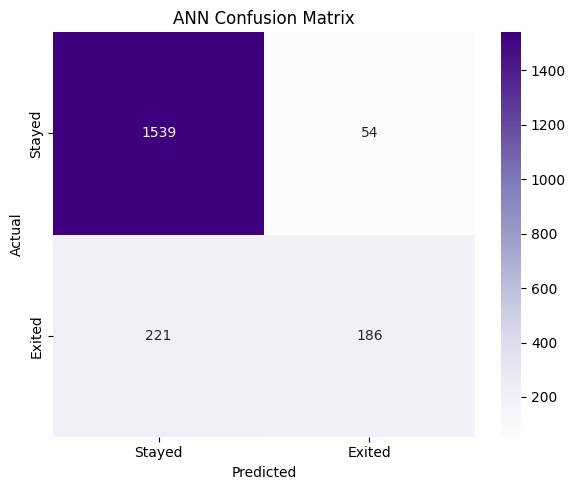

In [17]:
cm_ann = confusion_matrix(y_test_dl, y_pred_ann)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_ann,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Stayed", "Exited"],
    yticklabels=["Stayed", "Exited"]
)

plt.title("ANN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [18]:
# Save trained ANN model

MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

ANN_MODEL_PATH = MODEL_DIR / "bank_churn_ann.keras"

ann_model.save(ANN_MODEL_PATH)

# Save preprocessing pipeline separately
ANN_PREPROCESSOR_PATH = MODEL_DIR / "bank_churn_ann_preprocessor.pkl"

joblib.dump(preprocessor, ANN_PREPROCESSOR_PATH)

print("ANN model saved successfully!")
print("Model:", ANN_MODEL_PATH)
print("Preprocessor:", ANN_PREPROCESSOR_PATH)

ANN model saved successfully!
Model: c:\Users\navya\Documents\Bank-Customer-Churn\models\bank_churn_ann.keras
Preprocessor: c:\Users\navya\Documents\Bank-Customer-Churn\models\bank_churn_ann_preprocessor.pkl


In [19]:
# Compare Machine Learning and Deep Learning models

comparison_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Artificial Neural Network"
    ],

    "Category": [
        "Machine Learning",
        "Machine Learning",
        "Machine Learning",
        "Deep Learning"
    ],

    "Accuracy": [
        0.7135, 0.7420, 0.8510, ann_accuracy
    ],

    "Precision": [
        0.3872, 0.4183, 0.6477, ann_precision
    ],

    "Recall": [
        0.7002, 0.6855, 0.5872, ann_recall
    ],

    "F1 Score": [
        0.4987, 0.5196, 0.6160, ann_f1
    ],

    "ROC-AUC": [
        0.7772, 0.7614, 0.8584, ann_roc_auc
    ]
})

comparison_results.round(4)

,Model,Category,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,Machine Learning,0.7135,0.3872,0.7002,0.4987,0.7772
1,Decision Tree,Machine Learning,0.7420,0.4183,0.6855,0.5196,0.7614
2,Random Forest,Machine Learning,0.8510,0.6477,0.5872,0.6160,0.8584
3,Artificial Neural Network,Deep Learning,0.8625,0.7750,0.4570,0.5750,0.8648


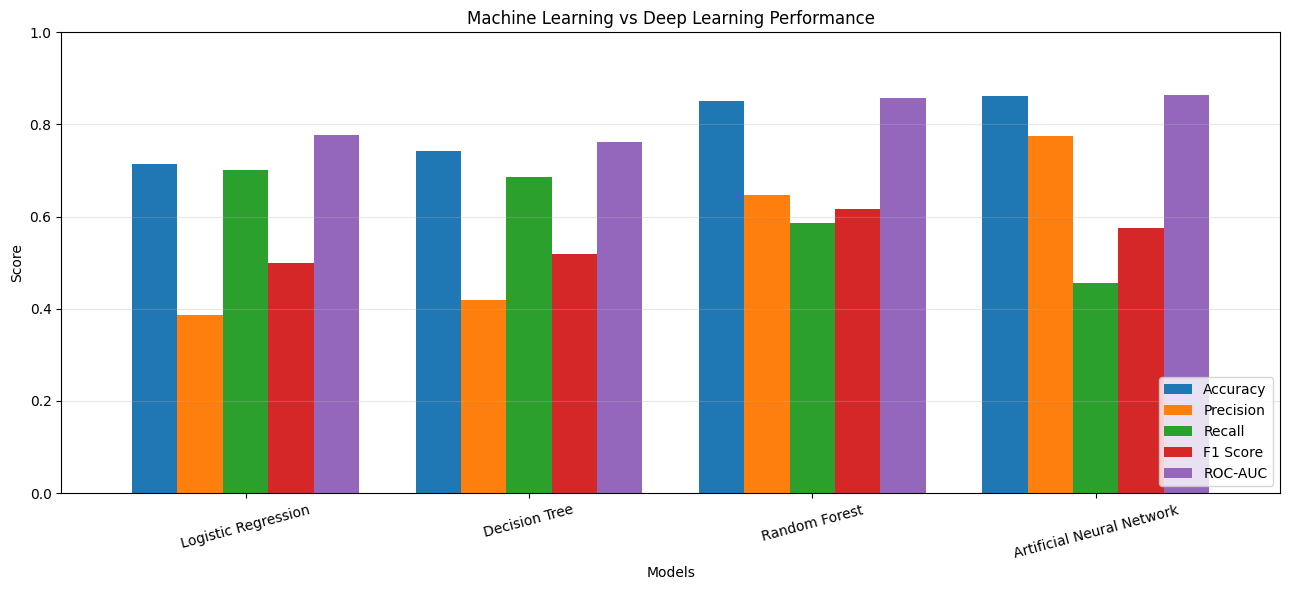

In [20]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

comparison_results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Machine Learning vs Deep Learning Performance")
plt.ylabel("Score")
plt.xlabel("Models")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
best_model = comparison_results.loc[
    comparison_results["F1 Score"].idxmax()
]

print("Best Model Based on F1 Score")
print("-----------------------------")
print("Model:", best_model["Model"])
print("Category:", best_model["Category"])
print("F1 Score:", round(best_model["F1 Score"], 4))

Best Model Based on F1 Score
-----------------------------
Model: Random Forest
Category: Machine Learning
F1 Score: 0.616


In [22]:
REPORT_DIR = BASE_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

comparison_results.to_csv(
    REPORT_DIR / "ml_dl_model_comparison.csv",
    index=False
)

print("ML vs DL comparison saved successfully!")

ML vs DL comparison saved successfully!
